<a href="https://colab.research.google.com/github/andres-merino/FormatoBaseProyectos/blob/main/Plantilla.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Carrera de Ciencia de Datos</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Asignatura &bull; Tema
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Andrés Merino &bull; 2025-01
            </font></p>
        </td>  
    </tr>
</table>

# Reto No. 1: Aprendizaje No Supervisado - Gestión de Residuos
**Equipo:** Grupo I

**Pregunta esencial:** ¿Qué perfiles de gestión de residuos aparecen en los registros municipales del Ecuador y cómo comunicar sus diferencias para orientar preguntas y propuestas de mejora?

**Alcance:** Análisis exploratorio de la base de datos GIRS 2024 del INEC para descubrir perfiles mediante algoritmos de agrupamiento no supervisado. No constituye un ranking de desempeño.

**Técnicas utilizadas:**
Se aplicarán K-Means y Agrupamiento Jerárquico para formar los clústeres, evaluando la calidad con el coeficiente de silueta. Posteriormente, se utilizará Análisis de Componentes Principales (PCA) estrictamente para la visualización en 2D.

Los paquetes necesarios son:

In [12]:
# Paquetes necesarios
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

---
## <font color='264CC7'> Lectura de datos </font>


Auditoría inicial de la base de datos:
Dimensiones (filas, columnas): (221, 213)

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 221 entries, 0 to 220
Columns: 213 entries, CantonId to MGDSP
dtypes: float64(128), int64(51), object(34)
memory usage: 367.9+ KB

Descripción de variables seleccionadas:


,VB,CSB,CRR,TROT,RI
count,221.000000,216.000000,221.000000,221.000000,2.210000e+02
mean,80.217602,0.842361,1926.724887,161.434661,1.223239e+04
std,362.055804,0.264634,9292.602631,823.842396,9.741990e+04
min,0.000000,0.000000,15.300000,0.000000,0.000000e+00
25%,9.070000,0.700000,136.800000,0.000000,0.000000e+00
50%,18.110000,1.000000,369.300000,0.000000,0.000000e+00
75%,46.010000,1.000000,1050.000000,3.600000,1.041670e+03
max,4840.000000,2.130000,121905.600000,9939.790000,1.420069e+06


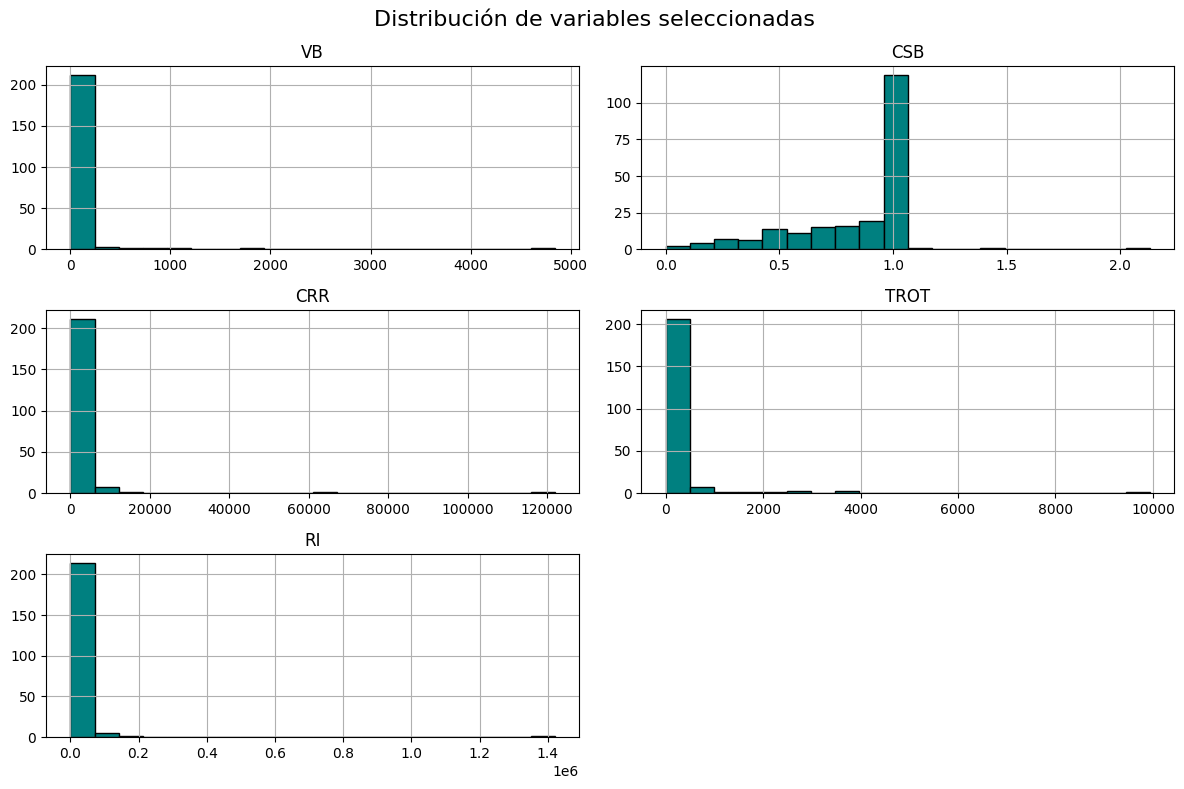

In [13]:

# Carga de datos cumpliendo las especificaciones del reto
df = pd.read_csv('BDD_GIRS_2024_VF.csv', sep=';', decimal=',', encoding='Windows-1252', dtype={'CantonId': str})

print("Auditoría inicial de la base de datos:")
print("Dimensiones (filas, columnas):", df.shape)
print("\nInformación general:")
df.info()

# Variables seleccionadas como punto de partida
features_cols = ['VB', 'CSB', 'CRR', 'TROT', 'RI']
print("\nDescripción de variables seleccionadas:")
display(df[features_cols].describe())

# Representación gráfica de distribuciones
df[features_cols].hist(bins=20, figsize=(12, 8), color='teal', edgecolor='black')
plt.suptitle('Distribución de variables seleccionadas', fontsize=16)
plt.tight_layout()
plt.show()

**Auditoría y Selección:**
Se verificó que la unidad de observación son los municipios. Se han elegido 5 características iniciales relacionadas con barrido, recolección y tratamiento, priorizando la cobertura de la gestión.


## <font color='264CC7'> Procesamiento de Datos </font>


In [14]:
from sklearn.preprocessing import StandardScaler

# Copia de seguridad
df_clean = df.copy()

# Tratamiento de faltantes y atípicos
# Asumimos que los nulos en TROT y RI significan ausencia de actividad reportada (0)
df_clean['TROT'] = df_clean['TROT'].fillna(0)
df_clean['RI'] = df_clean['RI'].fillna(0)

# Para CSB (cobertura), si hay valores nulos o superiores a 1, los imputamos temporalmente con la mediana para no perder registros
df_clean['CSB'] = df_clean['CSB'].apply(lambda x: 1.0 if x > 1 else x)
df_clean['CSB'] = df_clean['CSB'].fillna(df_clean['CSB'].median())

# Rellenar faltantes restantes en variables seleccionadas con la mediana
for col in ['VB', 'CRR']:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Escalado de datos
X = df_clean[features_cols]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Registros conservados para el clustering: {X_scaled.shape[0]}")

Registros conservados para el clustering: 221


## <font color='264CC7'> Análisis con Clustering </font>


--- Comparación de algoritmos ---
k=2 | Silueta K-Means: 0.9333 | Silueta Jerárquico: 0.9333
k=3 | Silueta K-Means: 0.6207 | Silueta Jerárquico: 0.6384
k=4 | Silueta K-Means: 0.6232 | Silueta Jerárquico: 0.6302
k=5 | Silueta K-Means: 0.6517 | Silueta Jerárquico: 0.6373
k=6 | Silueta K-Means: 0.6705 | Silueta Jerárquico: 0.6550


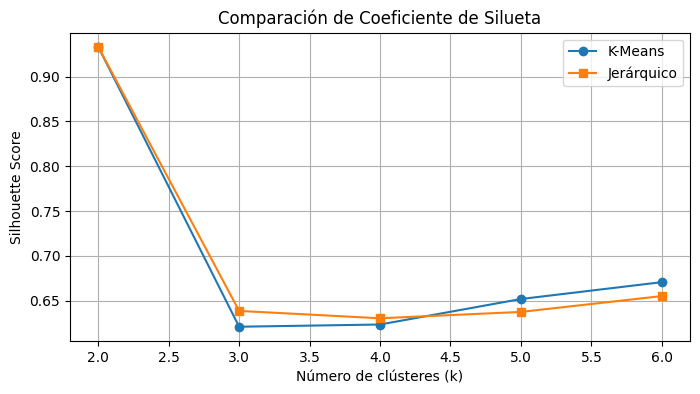


Tamaños de los grupos (K-Means):
Cluster
0    166
2     54
1      1
Name: count, dtype: int64


In [15]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

k_range = range(2, 7)
silhouette_km = []
silhouette_hc = []

print("--- Comparación de algoritmos ---")
for k in k_range:
    # K-Means con varias inicializaciones
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=15)
    labels_km = kmeans.fit_predict(X_scaled)
    sil_km = silhouette_score(X_scaled, labels_km)
    silhouette_km.append(sil_km)

    # Jerárquico (Ward, Euclidiana)
    hc = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward')
    labels_hc = hc.fit_predict(X_scaled)
    sil_hc = silhouette_score(X_scaled, labels_hc)
    silhouette_hc.append(sil_hc)

    print(f"k={k} | Silueta K-Means: {sil_km:.4f} | Silueta Jerárquico: {sil_hc:.4f}")

# Gráfico comparativo
plt.figure(figsize=(8, 4))
plt.plot(k_range, silhouette_km, marker='o', label='K-Means')
plt.plot(k_range, silhouette_hc, marker='s', label='Jerárquico')
plt.title('Comparación de Coeficiente de Silueta')
plt.xlabel('Número de clústeres (k)')
plt.ylabel('Silhouette Score')
plt.legend()
plt.grid(True)
plt.show()

# Selección del modelo final (ajusta k_optimo según el gráfico, usualmente 3 o 4)
k_optimo = 3
modelo_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=15)
df_clean['Cluster'] = modelo_final.fit_predict(X_scaled)

print("\nTamaños de los grupos (K-Means):")
print(df_clean['Cluster'].value_counts())

## <font color='264CC7'> Reducción de Dimensiones </font>


Varianza explicada individual: [0.56598115 0.21229389]
Varianza explicada acumulada: 0.7783


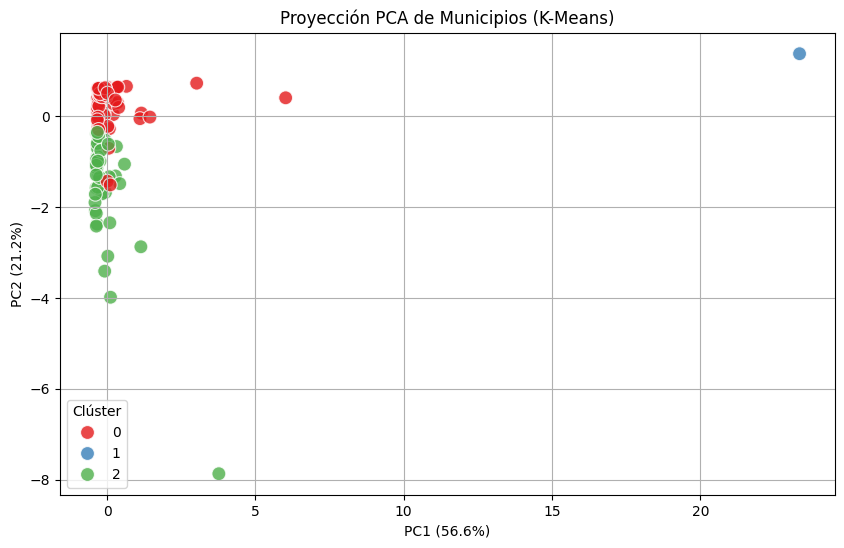


Contribución de variables a las componentes:


,VB,CSB,CRR,TROT,RI
PC1,0.579650,0.026638,0.576749,0.082667,0.569055
PC2,0.017901,0.736428,0.030397,-0.675437,0.014605


In [16]:
from sklearn.decomposition import PCA

# Aplicar PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(f"Varianza explicada individual: {pca.explained_variance_ratio_}")
print(f"Varianza explicada acumulada: {pca.explained_variance_ratio_.sum():.4f}")

# Visualización
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df_clean['Cluster'], palette='Set1', s=100, alpha=0.8)
plt.title('Proyección PCA de Municipios (K-Means)')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.legend(title='Clúster')
plt.grid(True)
plt.show()

# Contribuciones
contribuciones = pd.DataFrame(pca.components_, columns=features_cols, index=['PC1', 'PC2'])
print("\nContribución de variables a las componentes:")
display(contribuciones)